# 03 — Regression: predicting the Apnea-Hypopnea Index (IAH)

**Input:** `../data/processed/OSA_DB_UPM.xlsx` (637 patients, output of `src/01_data_preparation.py`)
**Output:** results table in `../results/`, figures in `../figures/`

**Question:** how well can IAH be predicted from easily collected clinical variables (gender, age, weight, height, neck circumference, BMI)?

**Method**
1. Hold out a test set (20%) that is used only once, at the end.
2. On the training set, compare several model families with 5-fold cross-validation, each with hyperparameter tuning (GridSearchCV).
3. Each model is tested with two targets: raw IAH, and log(1 + IAH) (the EDA showed IAH is strongly right-skewed). Predictions are always converted back to IAH, so all errors are in events/hour.
4. Compare with a baseline that always predicts the mean IAH.
5. Evaluate the best model on the test set and interpret it.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
SEED = 42
DATA = Path("../data/processed/OSA_DB_UPM.xlsx")
FIG = Path("../figures"); FIG.mkdir(parents=True, exist_ok=True)
RES = Path("../results"); RES.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")

## 1. Data and features
- `Male` encodes gender as 0/1 (models need numbers).
- `BMI` is recomputed from weight and height (feature engineering).

In [2]:
df = pd.read_excel(DATA)
df["Male"] = (df["Gender"] == "hombre").astype(int)
df["BMI"] = df["Weight"] / (df["Height"] / 100) ** 2

FEATURES = ["Male", "Age", "Weight", "Height", "Cervical", "BMI"]
X = df[FEATURES]
y = df["IAH"]
print(X.shape)
X.head()

(637, 6)


,Male,Age,Weight,Height,Cervical,BMI
0,1,56,119,174,48.0,39.305060
1,1,39,78,168,42.0,27.636054
2,1,32,80,173,40.0,26.729927
3,1,32,109,190,42.0,30.193906
4,1,39,86,169,42.0,30.110991


## 2. Train / test split
80% training, 20% test. The split is stratified on IAH quintiles so that both sets contain the same mix of mild and severe patients (IAH is skewed, a purely random split could put most severe cases on one side).

In [3]:
strata = pd.qcut(y, q=5, labels=False)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=strata)
print(f"Train: {len(X_train)} patients   Test: {len(X_test)} patients")
print(f"Mean IAH  train: {y_train.mean():.1f}   test: {y_test.mean():.1f}")

Train: 509 patients   Test: 128 patients
Mean IAH  train: 20.4   test: 20.3


## 3. Models and hyperparameters
Each model is a `Pipeline`. Models based on distances or coefficient sizes (linear, SVR, KNN) need standardised inputs, so a `StandardScaler` is included: it is fitted inside each cross-validation fold, which avoids information leaking from validation data.

| Model | Idea | Hyperparameters tuned |
|---|---|---|
| Baseline | always predicts the mean IAH | – |
| Linear regression | IAH = w0 + w1·x1 + … (least squares) | – |
| Ridge | linear + L2 penalty on weights (stable with correlated inputs) | alpha |
| Lasso | linear + L1 penalty (can set weights to 0 = variable selection) | alpha |
| Decision tree | if/then splits | max_depth, min_samples_leaf |
| Random Forest | average of many trees (lower variance) | n_estimators, max_depth, min_samples_leaf |
| XGBoost | trees added one by one to correct previous errors (boosting) | n_estimators, max_depth, learning_rate |
| SVR | kernel model, ignores errors smaller than epsilon | C, epsilon, gamma |
| KNN | mean IAH of the k most similar patients | n_neighbors |

In [4]:
scaled = lambda m: Pipeline([("scale", StandardScaler()), ("model", m)])
plain = lambda m: Pipeline([("model", m)])

MODELS = {
    "Baseline (mean)": (plain(DummyRegressor(strategy="mean")), {}),
    "Linear regression": (scaled(LinearRegression()), {}),
    "Ridge": (scaled(Ridge()), {"model__alpha": [0.1, 1, 10, 100]}),
    "Lasso": (scaled(Lasso(max_iter=10000)), {"model__alpha": [0.01, 0.1, 0.5, 1]}),
    "Decision tree": (plain(DecisionTreeRegressor(random_state=SEED)),
                      {"model__max_depth": [2, 3, 4, 6], "model__min_samples_leaf": [10, 20, 40]}),
    "Random Forest": (plain(RandomForestRegressor(random_state=SEED, n_jobs=-1)),
                      {"model__n_estimators": [300], "model__max_depth": [3, 5, None], "model__min_samples_leaf": [5, 10, 20]}),
    "XGBoost": (plain(XGBRegressor(random_state=SEED, n_jobs=-1, subsample=0.8)),
                {"model__n_estimators": [100, 300], "model__max_depth": [2, 3], "model__learning_rate": [0.03, 0.1]}),
    "SVR": (scaled(SVR()), {"model__C": [1, 10, 30], "model__epsilon": [1, 5], "model__gamma": ["scale", 0.05]}),
    "KNN": (scaled(KNeighborsRegressor()), {"model__n_neighbors": [5, 15, 30, 50]}),
}

## 4. Cross-validation on the training set
For every model and both targets (IAH and log(1 + IAH)), `GridSearchCV` tries every hyperparameter combination with 5-fold cross-validation and keeps the one with the lowest MAE. For the log target, `TransformedTargetRegressor` trains on log(1 + IAH) and converts predictions back with exp(x) − 1, so errors stay in events/hour.

*Note:* the score of the best combination is slightly optimistic (it was chosen on the same folds); the test set in Section 6 gives the unbiased estimate.

In [5]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2"}

def with_target(pipe, grid, target):
    if target == "IAH":
        return pipe, grid
    model = TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)
    return model, {f"regressor__{k}": v for k, v in grid.items()}

rows, best_models = [], {}
for name, (pipe, grid) in MODELS.items():
    for target in ["IAH", "log(1+IAH)"]:
        est, g = with_target(pipe, grid, target)
        search = GridSearchCV(est, g, cv=cv, scoring=SCORING, refit="MAE", n_jobs=-1)
        search.fit(X_train, y_train)
        i, r = search.best_index_, search.cv_results_
        rows.append({
            "Model": name, "Target": target,
            "MAE": -r["mean_test_MAE"][i], "MAE std": r["std_test_MAE"][i],
            "RMSE": -r["mean_test_RMSE"][i], "R2": r["mean_test_R2"][i], "R2 std": r["std_test_R2"][i],
            "Best params": {k.split("__")[-1]: v for k, v in search.best_params_.items()},
        })
        best_models[(name, target)] = search.best_estimator_

cv_results = pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True)
cv_results.to_csv(RES / "regression_cv_results.csv", index=False)
cv_results.round(3)

,Model,Target,MAE,MAE std,RMSE,R2,R2 std,Best params
0,SVR,IAH,12.205,0.945,17.393,0.118,0.042,"{'C': 10, 'epsilon': 1, 'gamma': 0.05}"
1,Random Forest,log(1+IAH),12.265,1.184,17.831,0.073,0.041,"{'max_depth': None, 'min_samples_leaf': 20, 'n..."
2,Linear regression,log(1+IAH),12.330,0.977,18.022,0.052,0.055,{}
3,Ridge,log(1+IAH),12.331,0.980,18.021,0.052,0.055,{'alpha': 0.1}
4,XGBoost,log(1+IAH),12.335,1.111,17.947,0.061,0.059,"{'learning_rate': 0.1, 'max_depth': 2, 'n_esti..."
5,Lasso,log(1+IAH),12.363,1.060,18.053,0.049,0.063,{'alpha': 0.01}
6,KNN,log(1+IAH),12.389,1.209,17.997,0.057,0.064,{'n_neighbors': 15}
7,Decision tree,log(1+IAH),12.473,1.184,17.835,0.073,0.047,"{'max_depth': 4, 'min_samples_leaf': 40}"
8,SVR,log(1+IAH),12.476,1.272,18.414,0.012,0.055,"{'C': 1, 'epsilon': 1, 'gamma': 0.05}"
9,Random Forest,IAH,12.729,0.680,16.795,0.175,0.033,"{'max_depth': None, 'min_samples_leaf': 20, 'n..."


## 5. Comparison of the models (cross-validation)

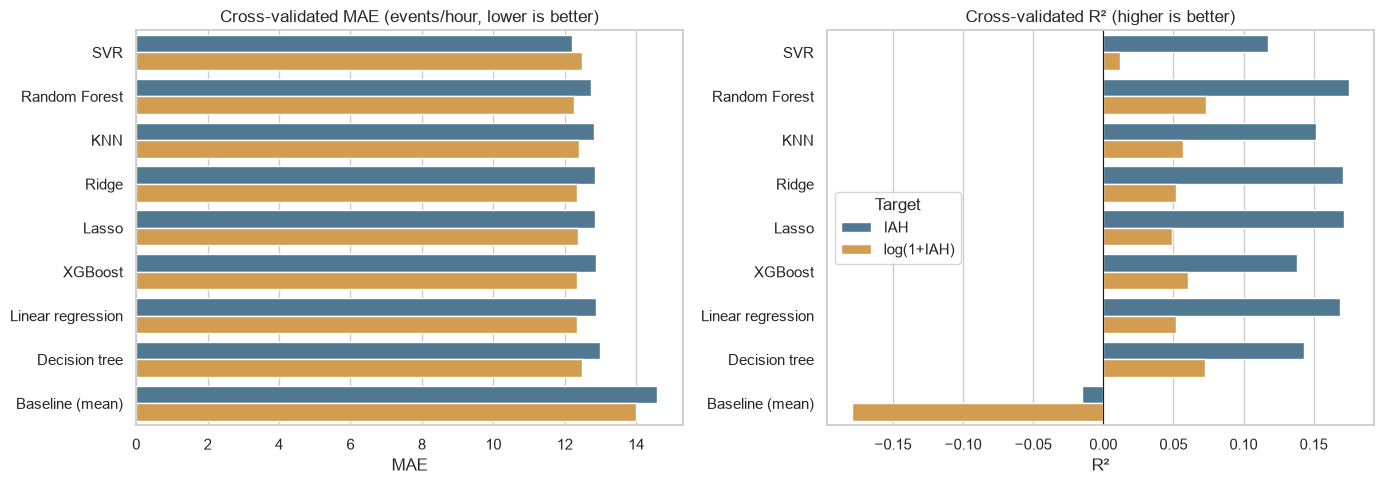

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
order = cv_results[cv_results.Target == "IAH"].sort_values("MAE")["Model"]
for ax, metric in zip(axes, ["MAE", "R2"]):
    sns.barplot(data=cv_results, y="Model", x=metric, hue="Target", order=order, ax=ax,
                palette={"IAH": "#457b9d", "log(1+IAH)": "#e9a03b"})
    ax.set_ylabel("")
axes[0].set(title="Cross-validated MAE (events/hour, lower is better)", xlabel="MAE")
axes[1].set(title="Cross-validated R² (higher is better)", xlabel="R²")
axes[1].axvline(0, color="k", lw=0.8)
axes[0].get_legend().remove(); axes[1].legend(title="Target", loc="center left")
plt.tight_layout(); plt.savefig(FIG / "reg_01_model_comparison.png", dpi=200); plt.show()

## 6. Final evaluation on the test set
The test set is used once, for the best model of each family selected above. These are the numbers to report.

In [7]:
test_rows = []
for (name, target), model in best_models.items():
    pred = model.predict(X_test)
    test_rows.append({"Model": name, "Target": target,
                      "MAE": mean_absolute_error(y_test, pred),
                      "RMSE": root_mean_squared_error(y_test, pred),
                      "R2": r2_score(y_test, pred)})
test_results = pd.DataFrame(test_rows).sort_values("MAE").reset_index(drop=True)
test_results.to_csv(RES / "regression_test_results.csv", index=False)
test_results.round(3)

,Model,Target,MAE,RMSE,R2
0,SVR,IAH,10.797,15.620,0.273
1,Linear regression,log(1+IAH),10.906,16.276,0.211
2,Ridge,log(1+IAH),10.911,16.289,0.210
3,Linear regression,IAH,10.977,15.008,0.329
4,Ridge,IAH,10.987,15.066,0.324
5,XGBoost,log(1+IAH),11.033,16.375,0.201
6,Random Forest,log(1+IAH),11.036,16.303,0.208
7,Lasso,log(1+IAH),11.037,16.665,0.173
8,Lasso,IAH,11.051,15.208,0.311
9,XGBoost,IAH,11.059,14.811,0.346


Best model (chosen by cross-validation): SVR on IAH


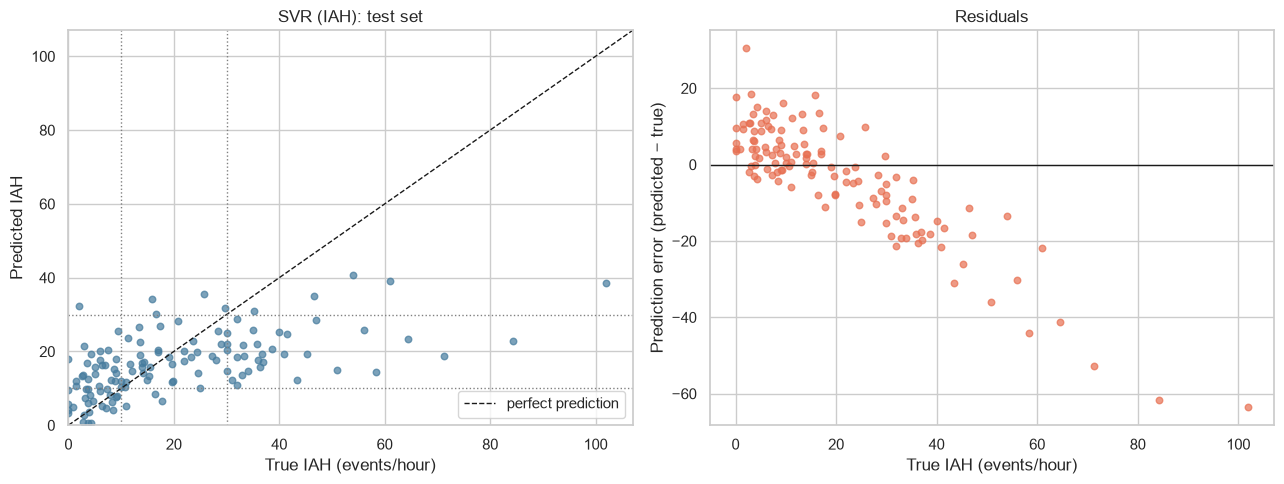

In [8]:
best_name, best_target = cv_results.iloc[0][["Model", "Target"]]
best = best_models[(best_name, best_target)]
pred = best.predict(X_test)
print(f"Best model (chosen by cross-validation): {best_name} on {best_target}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_test, pred, s=22, alpha=0.7, color="#457b9d")
lim = [0, max(y_test.max(), pred.max()) + 5]
axes[0].plot(lim, lim, "k--", lw=1, label="perfect prediction")
for t in (10, 30):
    axes[0].axvline(t, color="grey", ls=":", lw=1); axes[0].axhline(t, color="grey", ls=":", lw=1)
axes[0].set(xlim=lim, ylim=lim, xlabel="True IAH (events/hour)", ylabel="Predicted IAH",
            title=f"{best_name} ({best_target}): test set")
axes[0].legend()
axes[1].scatter(y_test, pred - y_test, s=22, alpha=0.7, color="#e76f51")
axes[1].axhline(0, color="k", lw=1)
axes[1].set(xlabel="True IAH (events/hour)", ylabel="Prediction error (predicted − true)", title="Residuals")
plt.tight_layout(); plt.savefig(FIG / "reg_02_best_model_test.png", dpi=200); plt.show()

## 7. Interpretation: which variables matter?
**a) Linear models.** With standardised inputs, each coefficient is the change in predicted IAH for +1 standard deviation of the variable. Comparing Linear regression (no penalty) and Lasso shows the effect of the correlated inputs (Weight, BMI, Height).

In [9]:
coef = pd.DataFrame({
    name: best_models[(name, "IAH")].named_steps["model"].coef_
    for name in ["Linear regression", "Ridge", "Lasso"]
}, index=FEATURES).round(2)
coef

,Linear regression,Ridge,Lasso
Male,0.54,0.47,0.08
Age,2.85,2.82,2.73
Weight,16.90,12.52,4.07
Height,-9.21,-6.81,-1.98
Cervical,4.72,4.80,5.01
BMI,-11.23,-7.37,0.00


**b) Permutation importance (best model, test set).** Shuffle one variable at a time and measure how much the MAE gets worse: the larger the increase, the more the model relies on that variable. This works for any model, including forests and boosting.

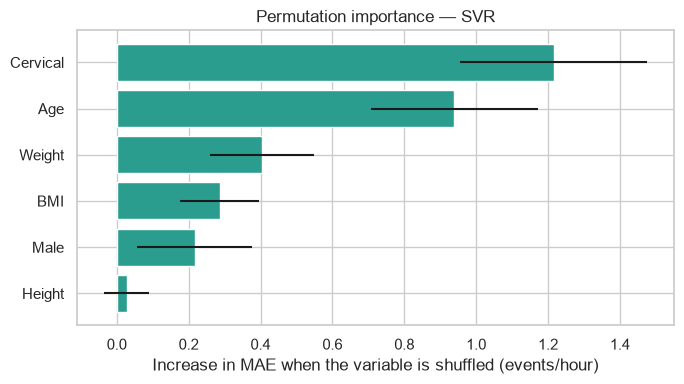

,Variable,MAE increase,std
4,Cervical,1.216,0.259
1,Age,0.939,0.232
2,Weight,0.404,0.145
5,BMI,0.286,0.111
0,Male,0.216,0.160
3,Height,0.027,0.062


In [10]:
imp = permutation_importance(best, X_test, y_test, scoring="neg_mean_absolute_error",
                             n_repeats=30, random_state=SEED)
importance = pd.DataFrame({"Variable": FEATURES, "MAE increase": imp.importances_mean,
                           "std": imp.importances_std}).sort_values("MAE increase", ascending=False)
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(importance["Variable"], importance["MAE increase"], xerr=importance["std"], color="#2a9d8f")
ax.invert_yaxis()
ax.set(xlabel="Increase in MAE when the variable is shuffled (events/hour)",
       title=f"Permutation importance — {best_name}")
plt.tight_layout(); plt.savefig(FIG / "reg_03_permutation_importance.png", dpi=200); plt.show()
importance.round(3)

## 8. Conclusions
*(to be written in the report from the outputs above)*